In [27]:
#Author : Gauri and Rinkal
import seaborn as sns 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reading input file 

In [28]:
import pandas as pd
# File details
file_name = "final_19"
base_path = '/kaggle/input/wind-turbine-dataset/'
file_path = f"{base_path}{file_name}.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

            time_stamp  asset_id  id train_test  status_type_id  sensor_0_avg  \
0  2022-02-02 00:00:00        11   0      train               0           0.0   
1  2022-02-02 00:10:00        11   1      train               0           0.0   
2  2022-02-02 00:20:00        11   2      train               0           0.0   
3  2022-02-02 00:30:00        11   3      train               0           0.0   
4  2022-02-02 00:40:00        11   4      train               0           0.0   

   sensor_0_max  sensor_0_min  sensor_0_std  sensor_1_avg  ...  \
0           0.0           0.0           0.0           0.0  ...   
1           0.0           0.0           0.0           0.0  ...   
2           0.0           0.0           0.0           0.0  ...   
3           0.0           0.0           0.0           0.0  ...   
4           0.0           0.0           0.0           0.0  ...   

   wind_speed_60_min  wind_speed_60_std  wind_speed_61_avg  wind_speed_61_max  \
0               3.34               

# Information about dataframe

In [29]:
# Getting summary of dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56274 entries, 0 to 56273
Columns: 257 entries, time_stamp to power_62_std
dtypes: float64(252), int64(3), object(2)
memory usage: 110.3+ MB
None


In [30]:
print(df.columns)

Index(['time_stamp', 'asset_id', 'id', 'train_test', 'status_type_id',
       'sensor_0_avg', 'sensor_0_max', 'sensor_0_min', 'sensor_0_std',
       'sensor_1_avg',
       ...
       'wind_speed_60_min', 'wind_speed_60_std', 'wind_speed_61_avg',
       'wind_speed_61_max', 'wind_speed_61_min', 'wind_speed_61_std',
       'power_62_avg', 'power_62_max', 'power_62_min', 'power_62_std'],
      dtype='object', length=257)


# Printing Data types of each columns

In [31]:
print(df.dtypes)

time_stamp            object
asset_id               int64
id                     int64
train_test            object
status_type_id         int64
                      ...   
wind_speed_61_std    float64
power_62_avg         float64
power_62_max         float64
power_62_min         float64
power_62_std         float64
Length: 257, dtype: object


# Train and test data samples checking

In [32]:
df["train_test"].value_counts()

train_test
train         52529
prediction     3745
Name: count, dtype: int64

# Balanced/unbalanced dataset checking

In [33]:
# Check the distribution of status_type_id and calculate Normal vs Anomaly labels
normal_values = [0, 2]
normal_count = df['status_type_id'].isin(normal_values).sum()
anomaly_count = len(df) - normal_count

# Print the counts of Normal and Anomaly
print(f"Normal count: {normal_count}")
print(f"Anomaly count: {anomaly_count}")

Normal count: 51647
Anomaly count: 4627


# Data preprocessing

# Removing unnecessary columns

In [34]:
#removing unnecessary columns

# Remove specified columns
columns_to_remove = ['asset_id', 'id']
df = df.drop(columns=columns_to_remove)


# Filling missing values in each columns

In [35]:
# Identify columns with missing values
missing_columns = df.columns[df.isnull().sum() > 0]

# Fill missing values with the median of each column
for column in missing_columns:
    median_value = df[column].median()
    df[column].fillna(median_value, inplace=True)

print("Missing values filled with the median of their respective columns.")

Missing values filled with the median of their respective columns.


# Correlation heatmap for first 20 sensors 

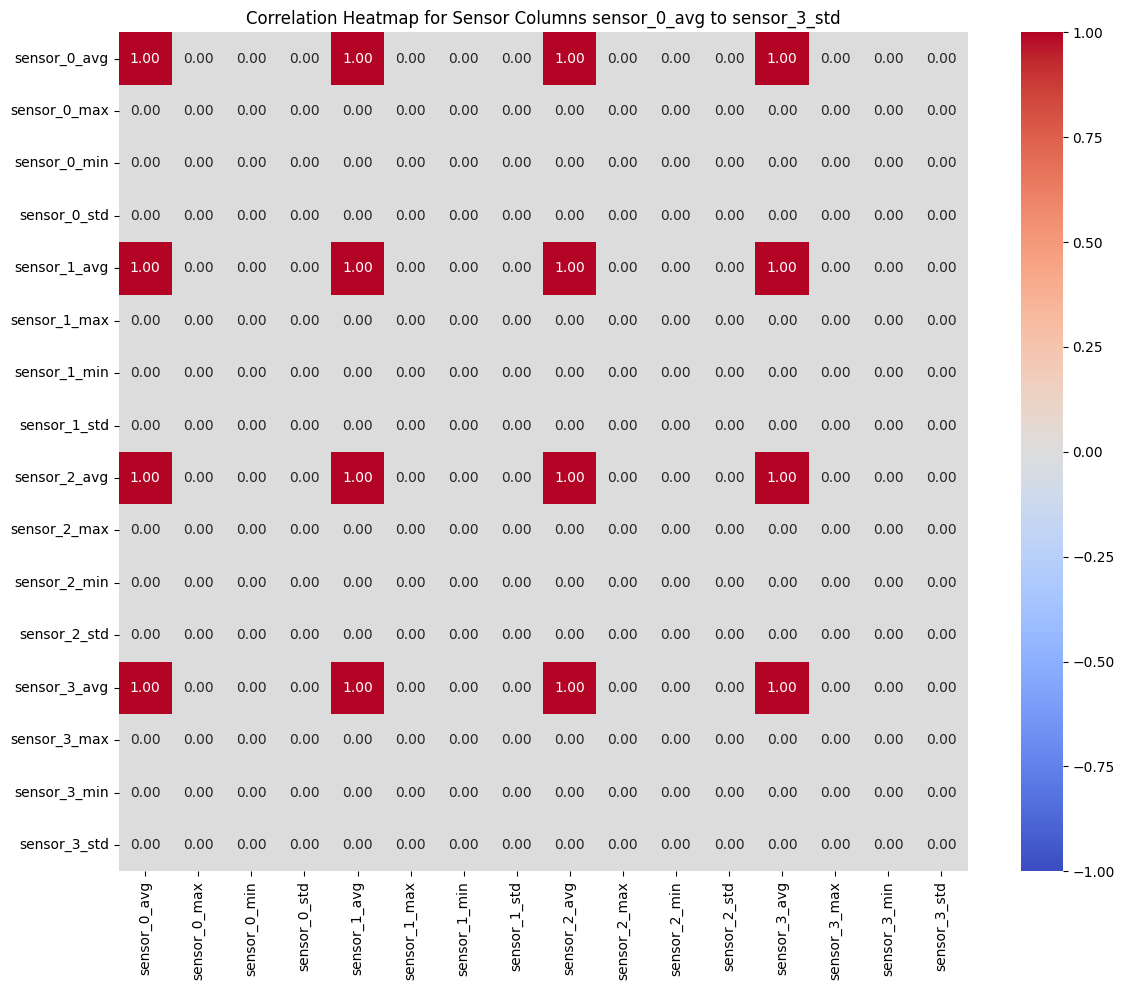

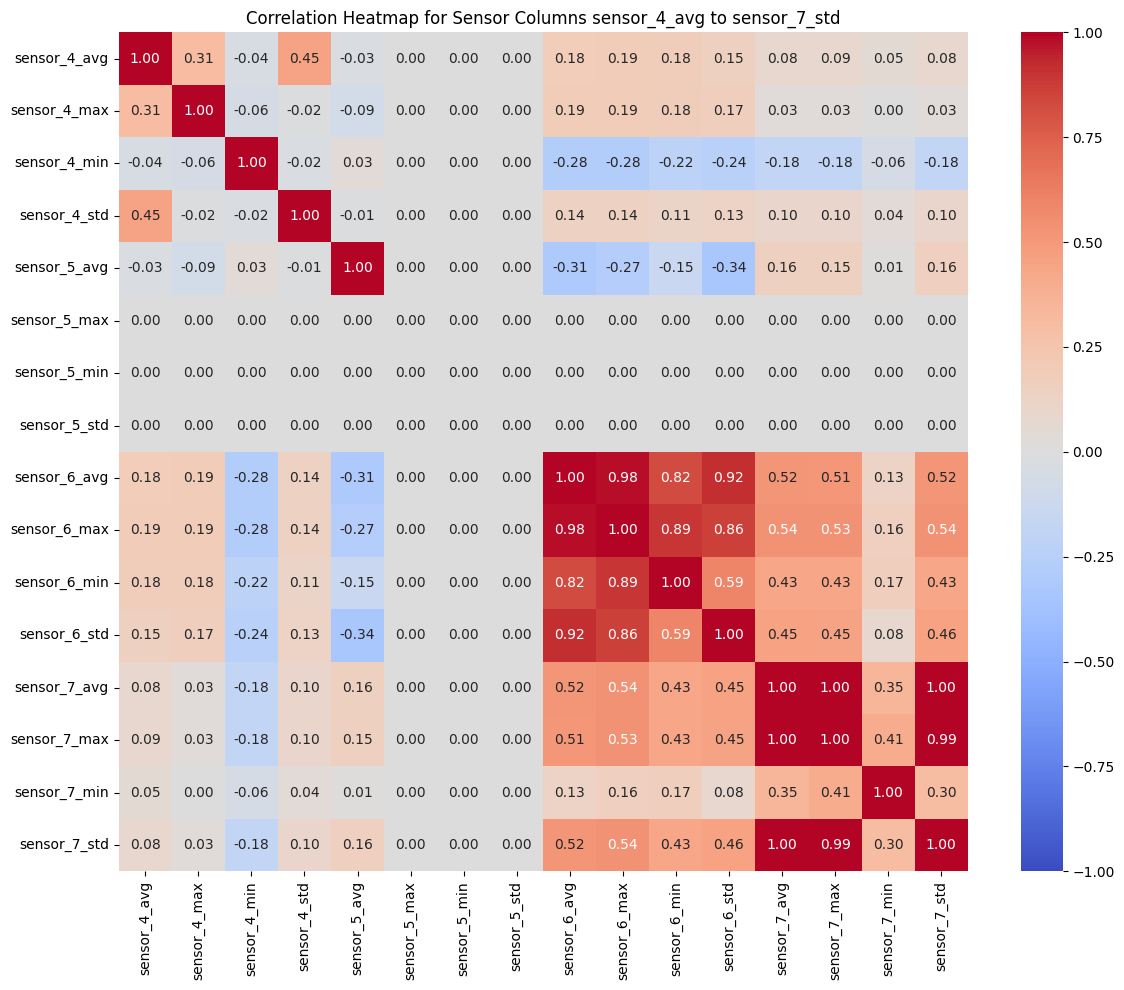

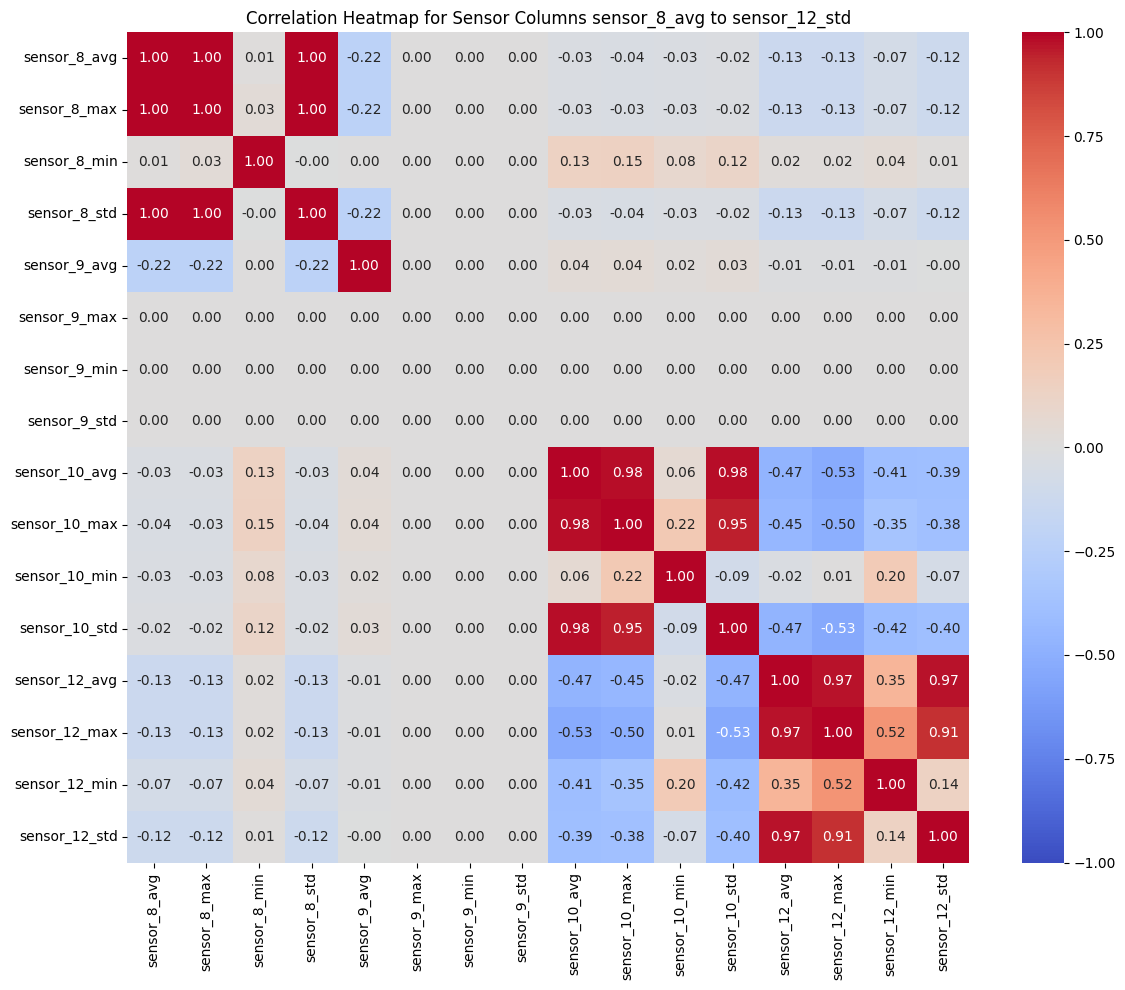

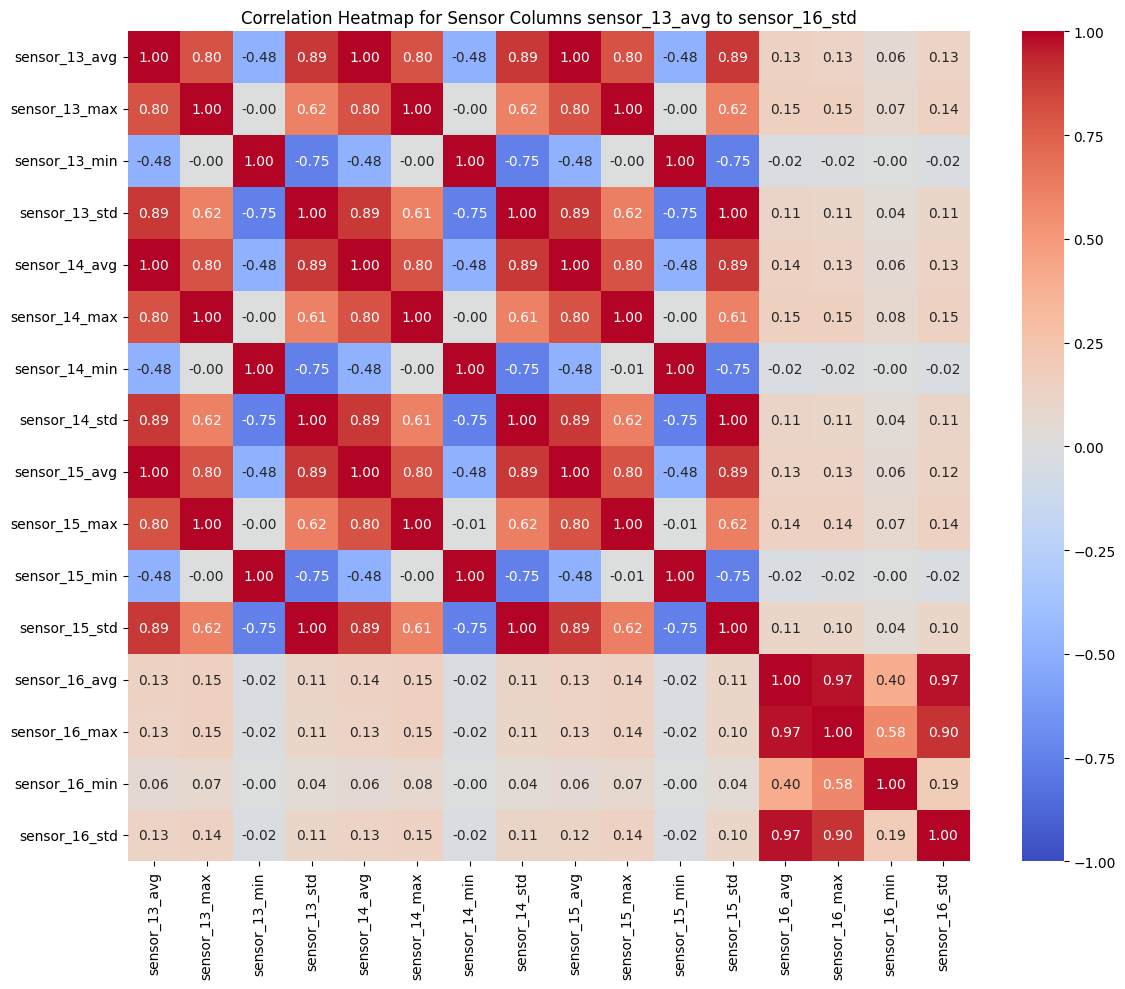

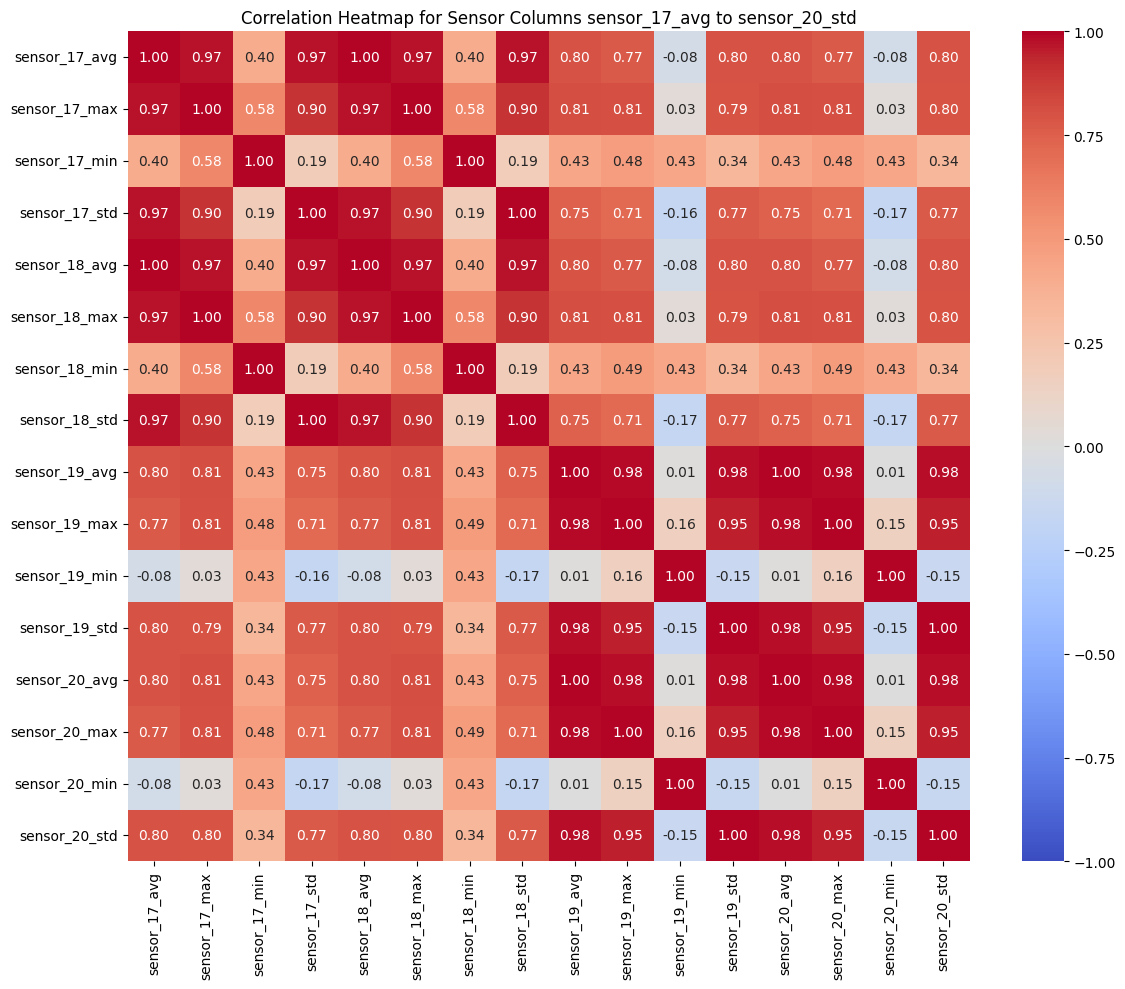

In [36]:
#Author : Gauri and Rinkal
import matplotlib.pyplot as plt
import seaborn as sns

# Identify sensor columns
sensor_columns = [col for col in df.columns if 'sensor_' in col]

# Define group size (16 columns per heatmap)
group_size = 16

# Split sensor columns into groups of 16
sensor_groups = [sensor_columns[i:i + group_size] for i in range(0, len(sensor_columns), group_size)]

# Merge the last group with the second-to-last group if the last group has fewer columns
if len(sensor_groups) > 1 and len(sensor_groups[-1]) < group_size:
    sensor_groups[-2].extend(sensor_groups[-1])
    sensor_groups.pop()  # Remove the now-empty last group

# Limit the processing to the first 5 groups
sensor_groups = sensor_groups[:5]

# Loop through each group and plot the correlation heatmap
for i, group in enumerate(sensor_groups):
    # Calculate the correlation matrix for the current group
    correlation_matrix = df[group].corr()
    
    # Fill missing values in the correlation matrix with zeros
    correlation_matrix = correlation_matrix.fillna(0)
    
    # Plot the heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
    plt.title(f"Correlation Heatmap for Sensor Columns {group[0]} to {group[-1]}")
    plt.tight_layout()
    plt.show()


# Timeseries plot for randomly taken 5 sensors ( x axis has 30 timestamp only for better visualization)

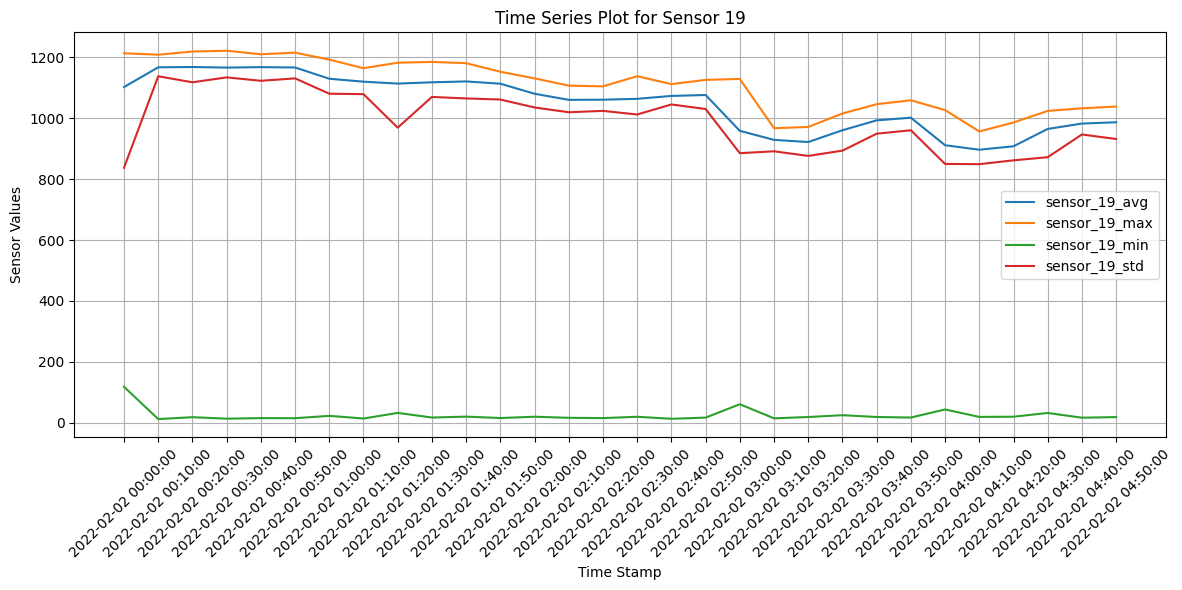

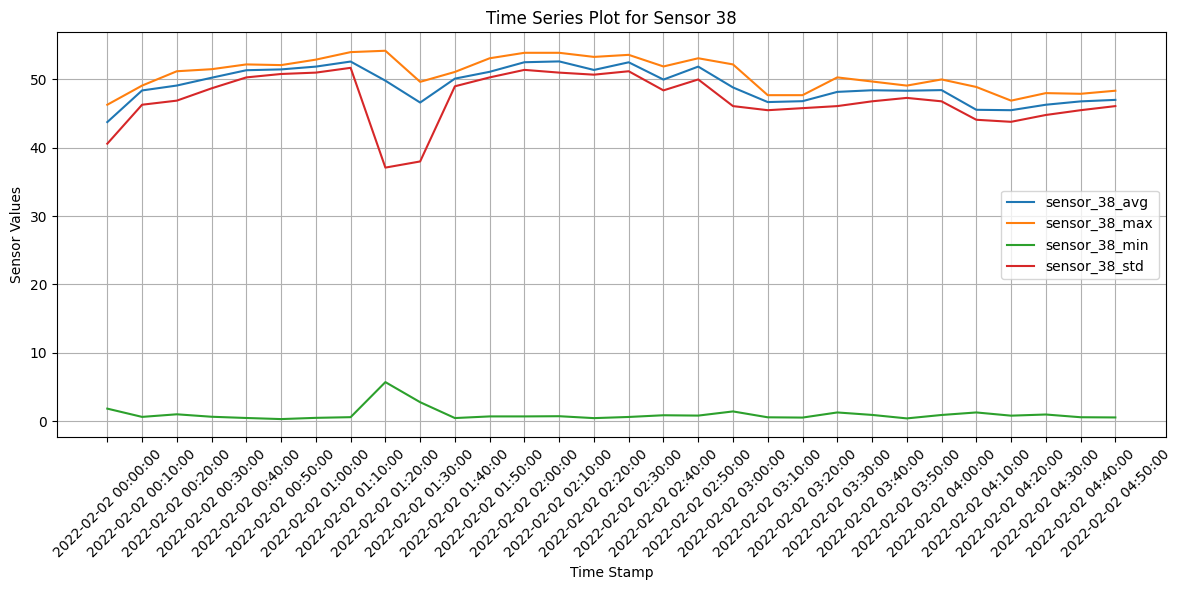

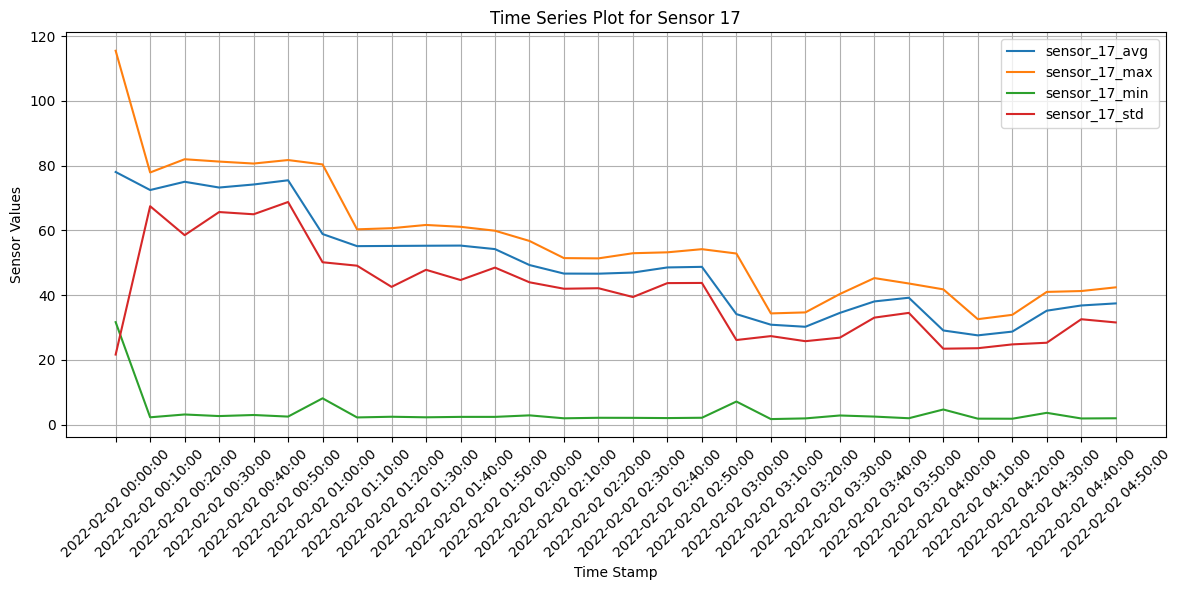

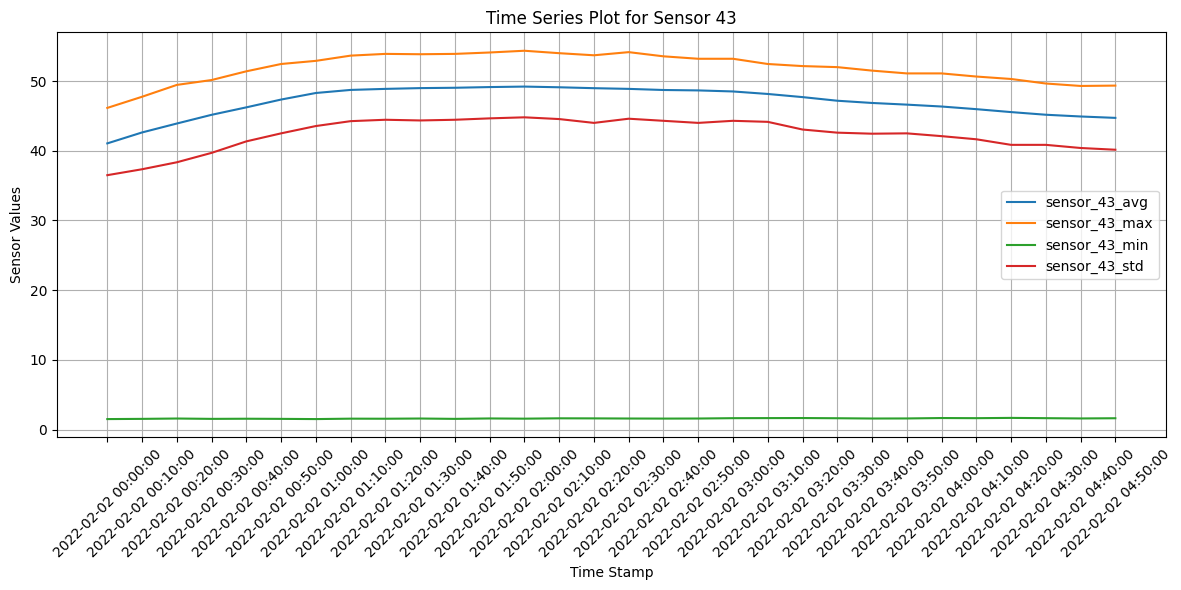

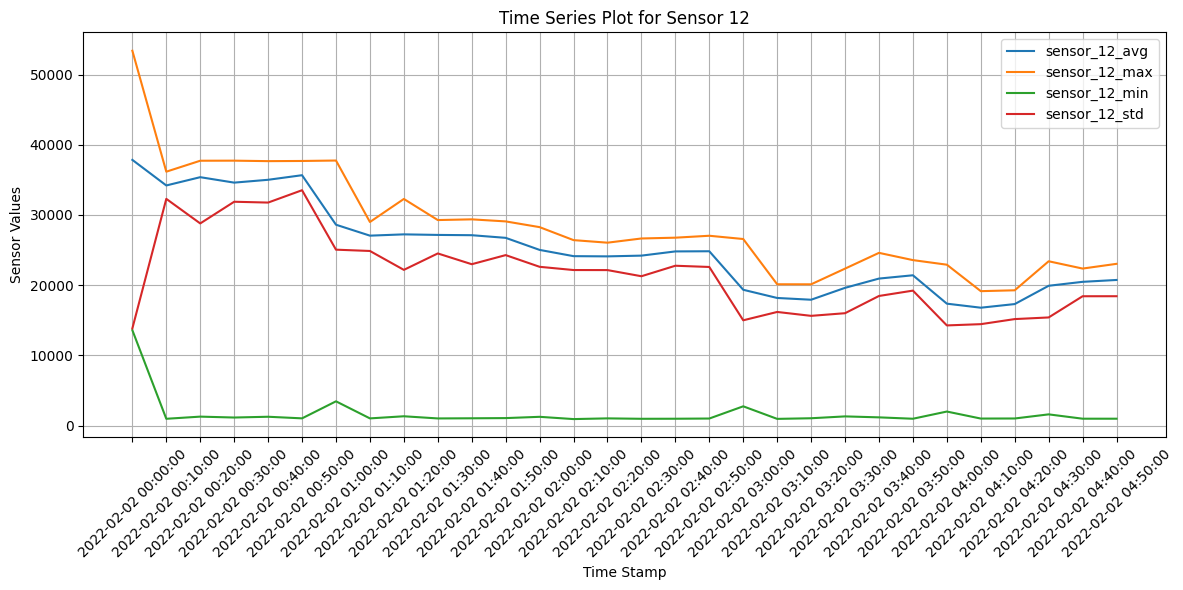

In [37]:
#Author : Gauri and Rinkal
import matplotlib.pyplot as plt
import random

# Select the first 30 rows for plotting
subset_df = df.iloc[:30]

# Select the time_stamp column for the x-axis
time_stamps = subset_df['time_stamp']

# Randomly select 5 sensor IDs
sensor_ids = list(set(col.split('_')[1] for col in sensor_columns))
random_sensor_ids = random.sample(sensor_ids, 5)

# Plot the 4 columns for each selected sensor in separate plots
for sensor_id in random_sensor_ids:
    # Identify the 4 columns associated with the current sensor
    sensor_group = [col for col in sensor_columns if f'sensor_{sensor_id}_' in col]
    
    # Plot the 4 columns
    plt.figure(figsize=(12, 6))
    for sensor in sensor_group:
        plt.plot(time_stamps, subset_df[sensor], label=sensor)
    
    # Customize the plot
    plt.xlabel('Time Stamp')
    plt.ylabel('Sensor Values')
    plt.title(f"Time Series Plot for Sensor {sensor_id}")
    plt.legend(loc='best')
    plt.xticks(rotation=45)
    plt.grid()
    plt.tight_layout()
    plt.show()


# plotting Mean values of randomly taken 4 sensors daily for all days

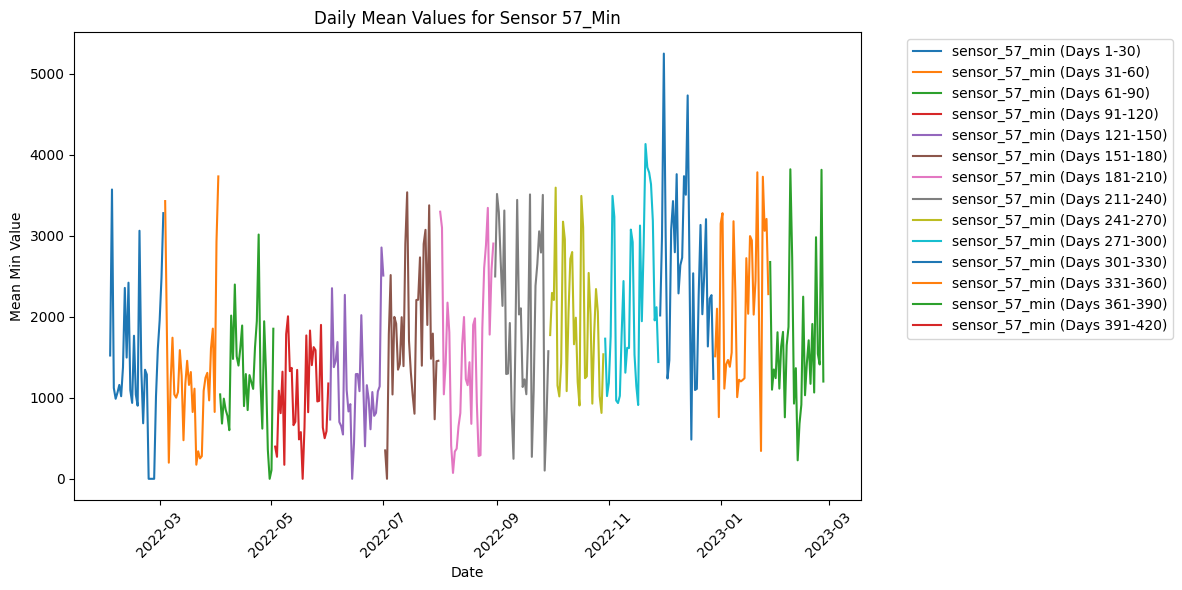

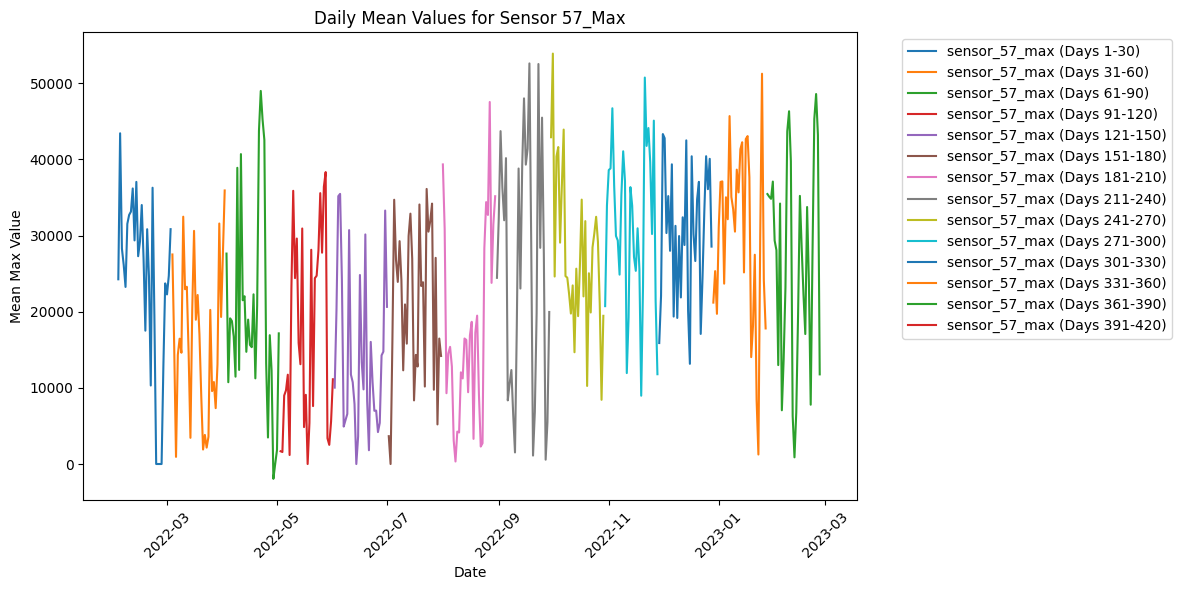

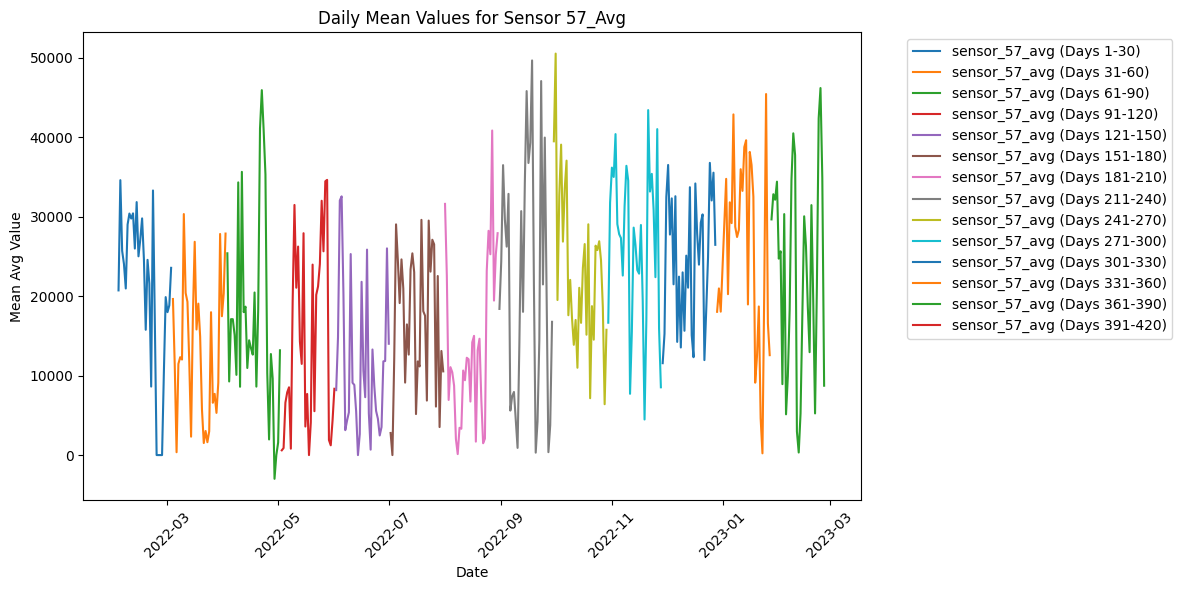

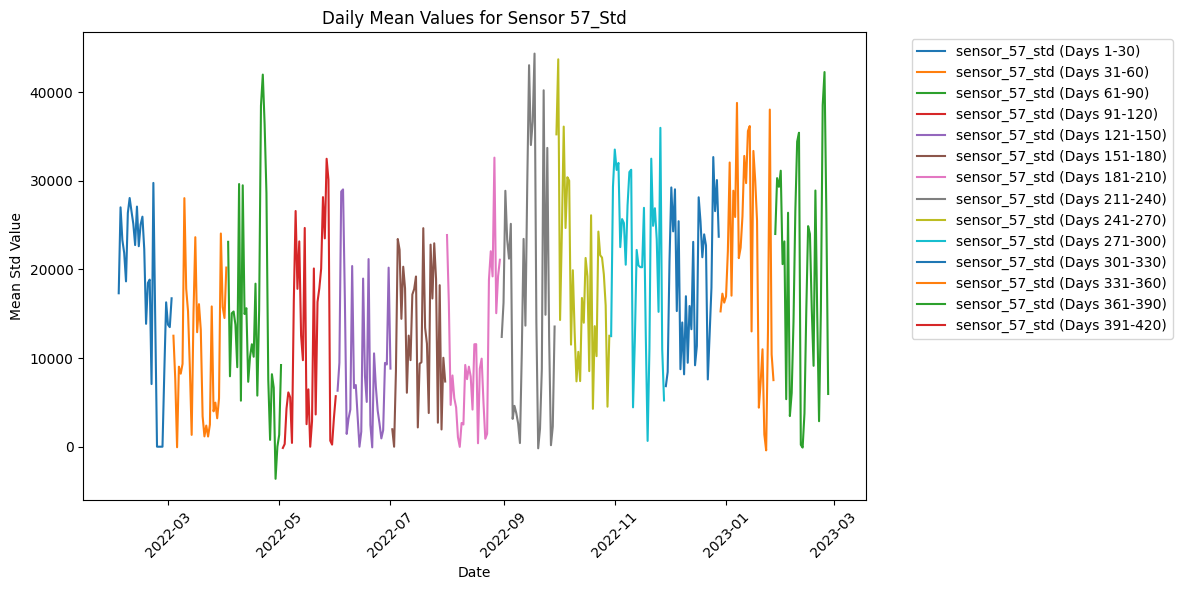

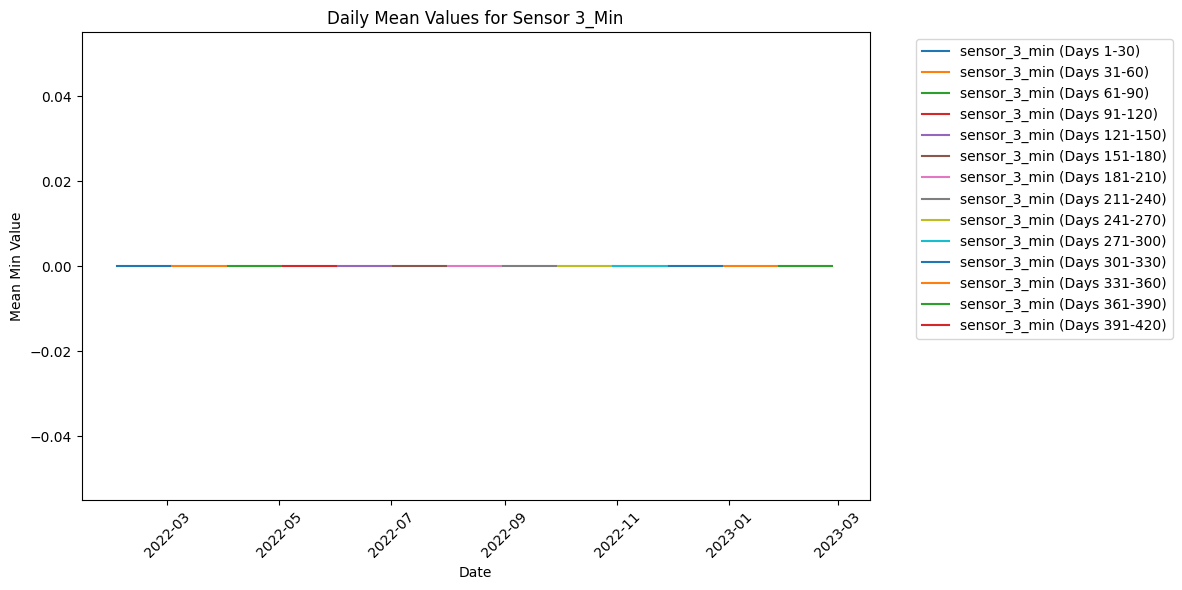

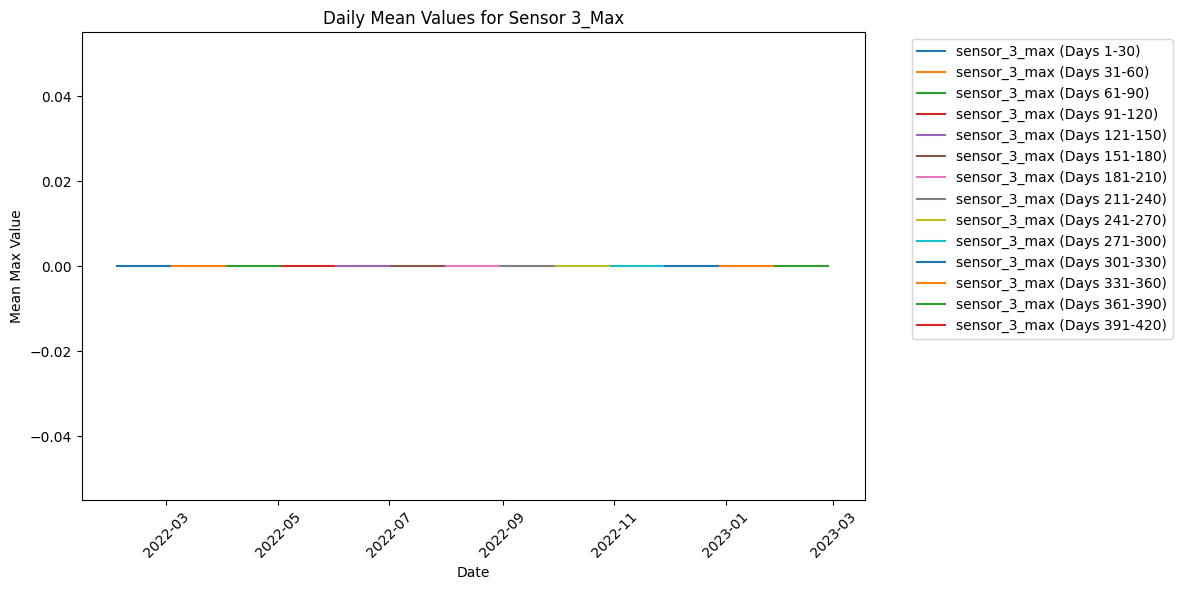

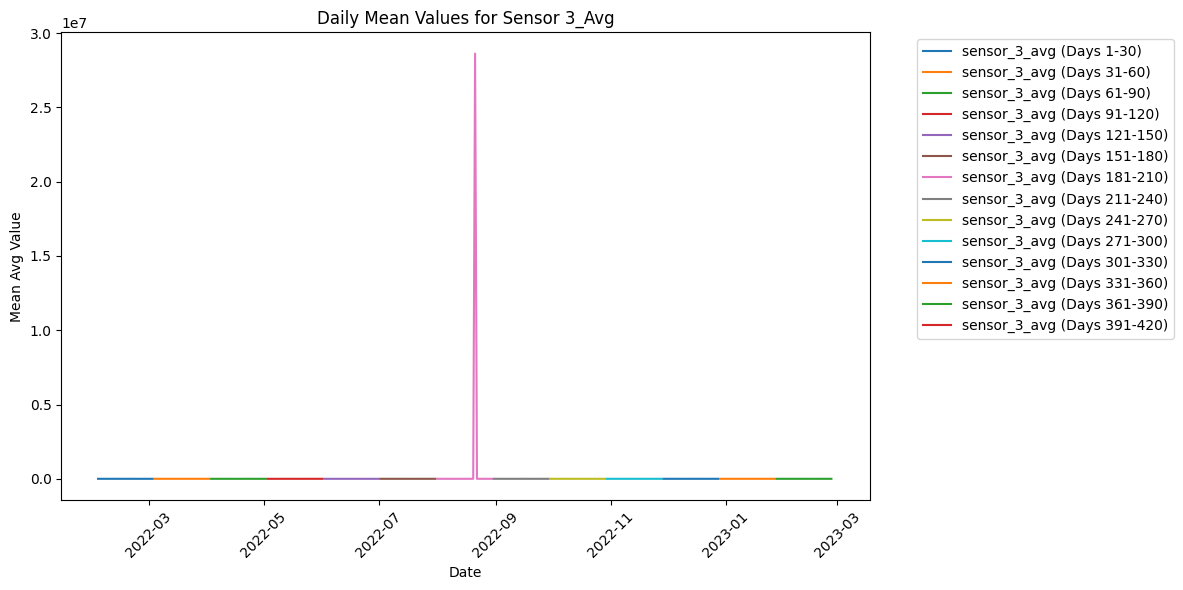

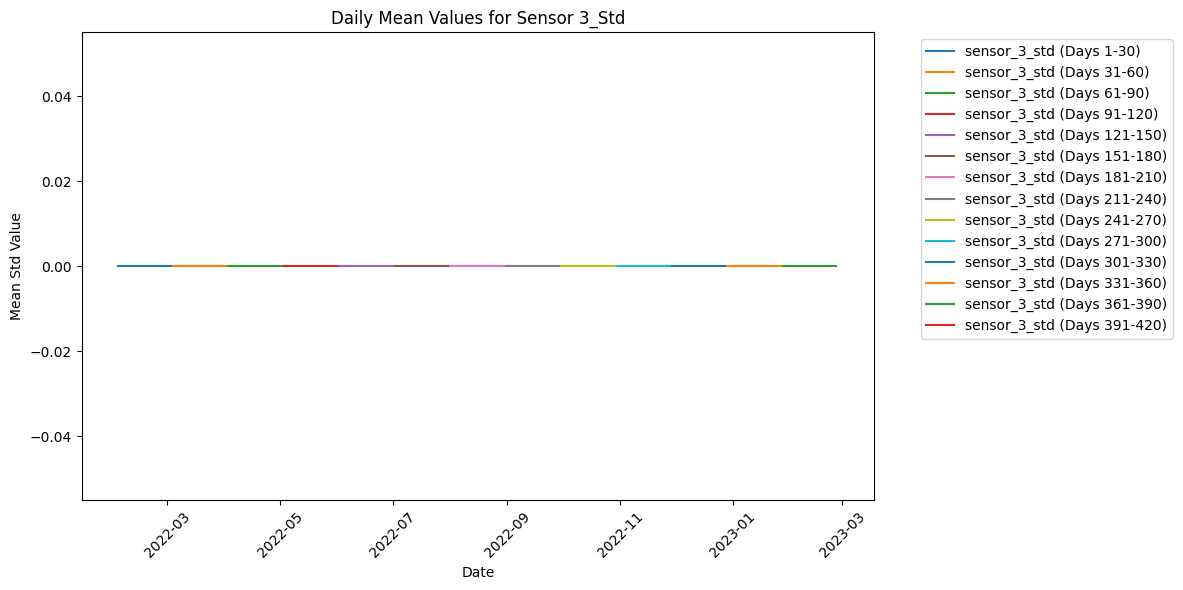

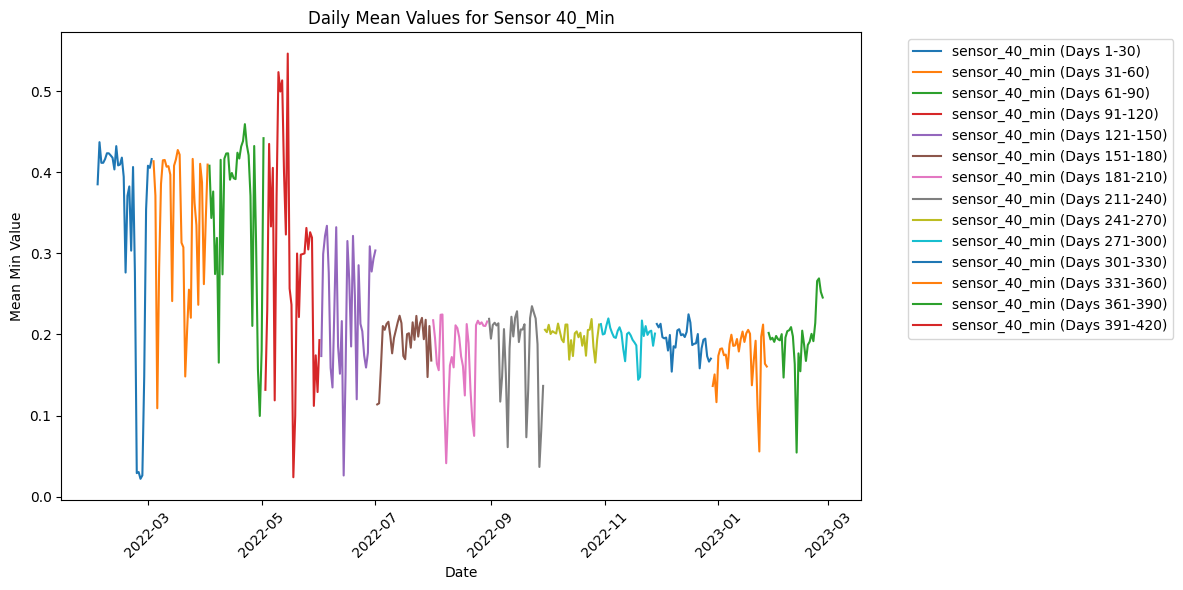

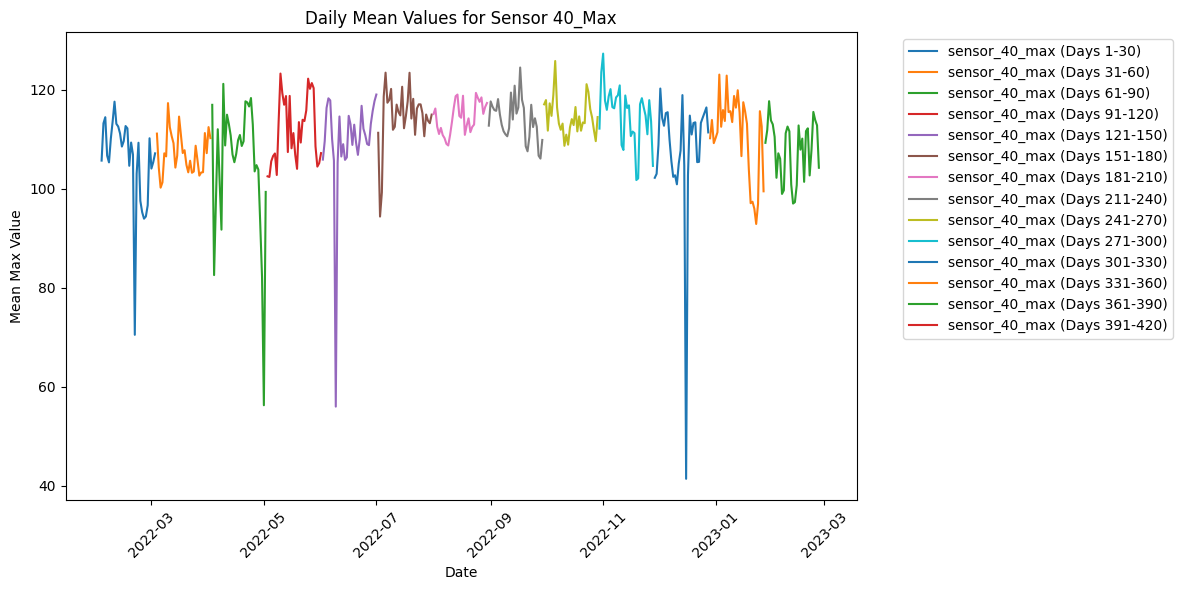

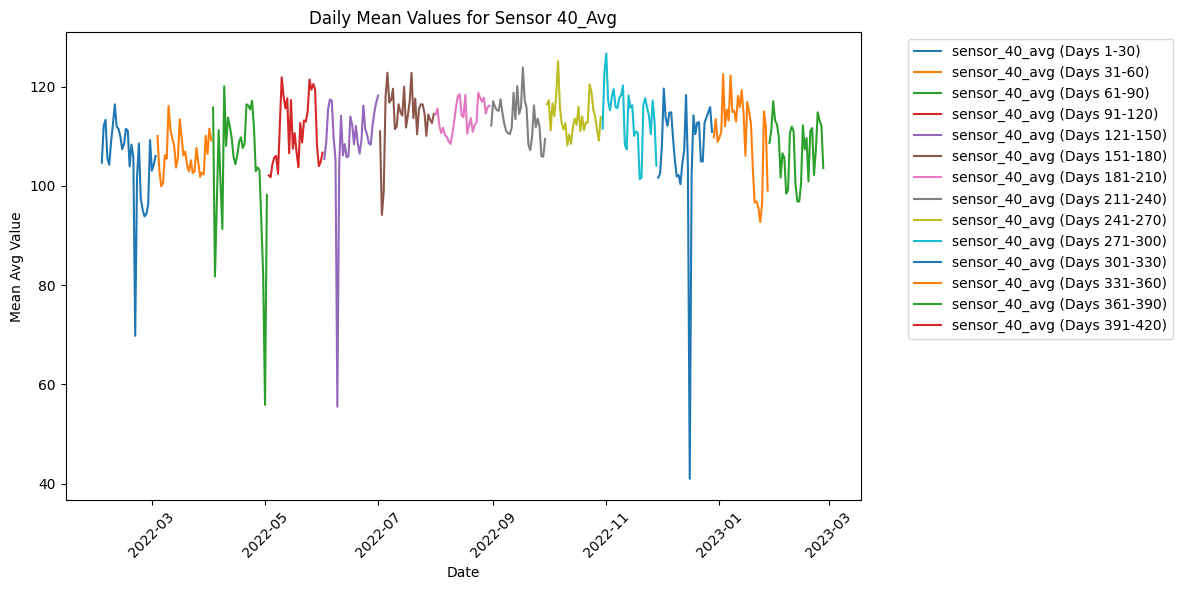

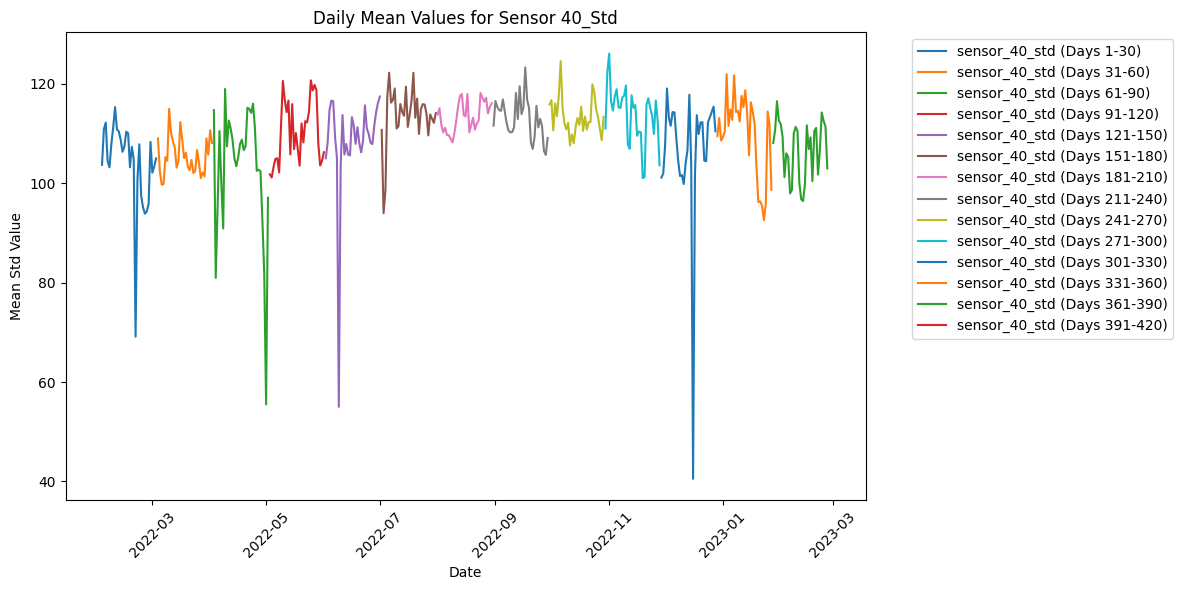

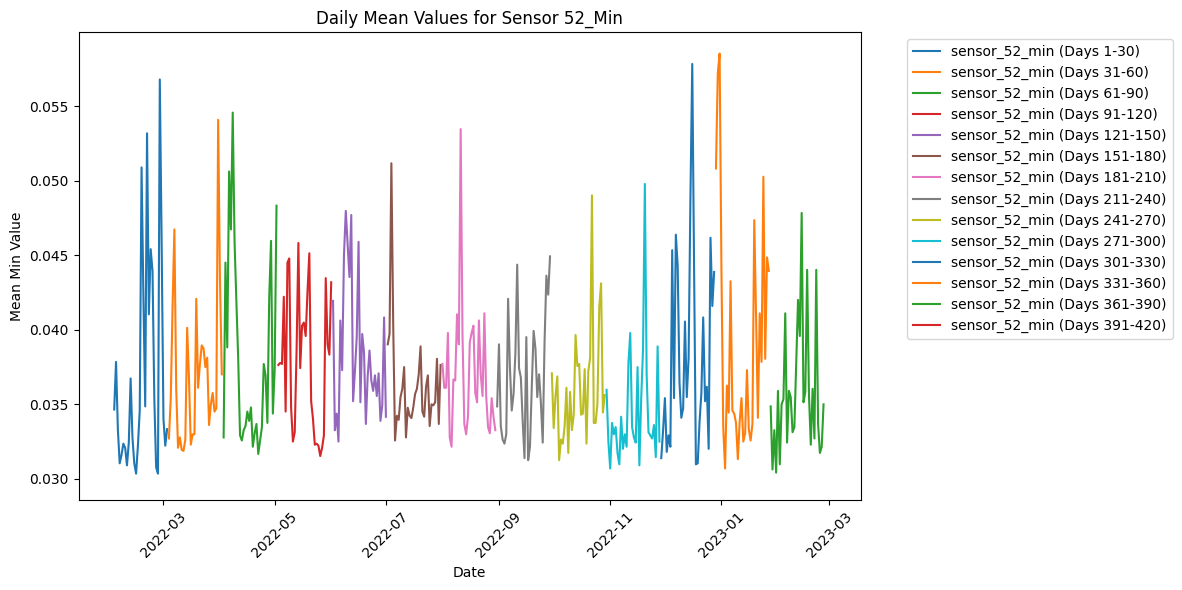

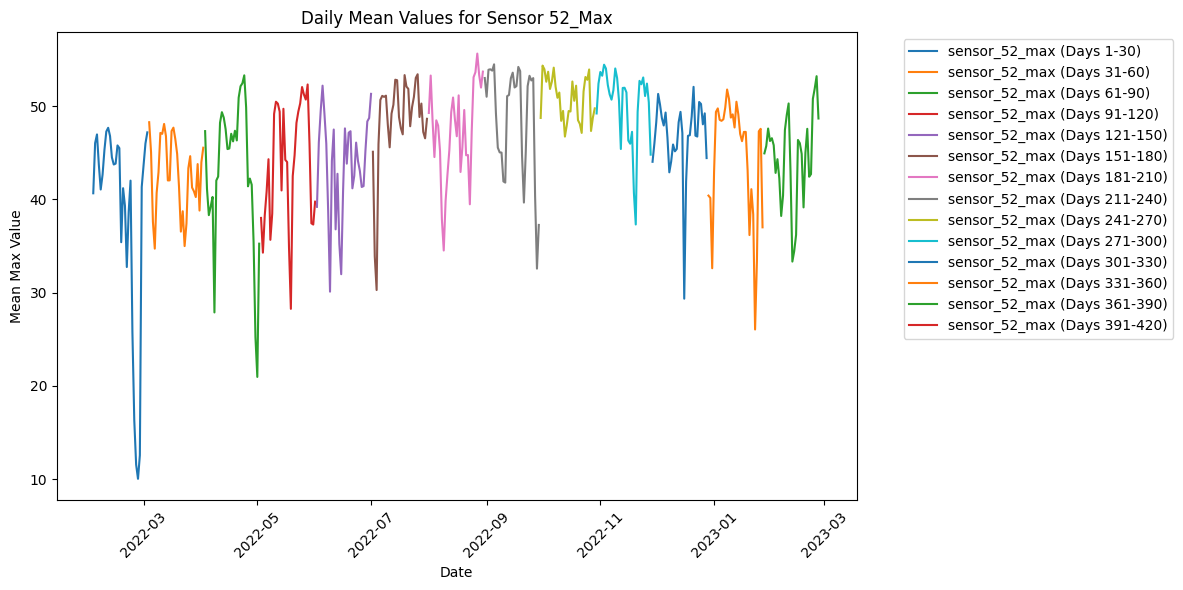

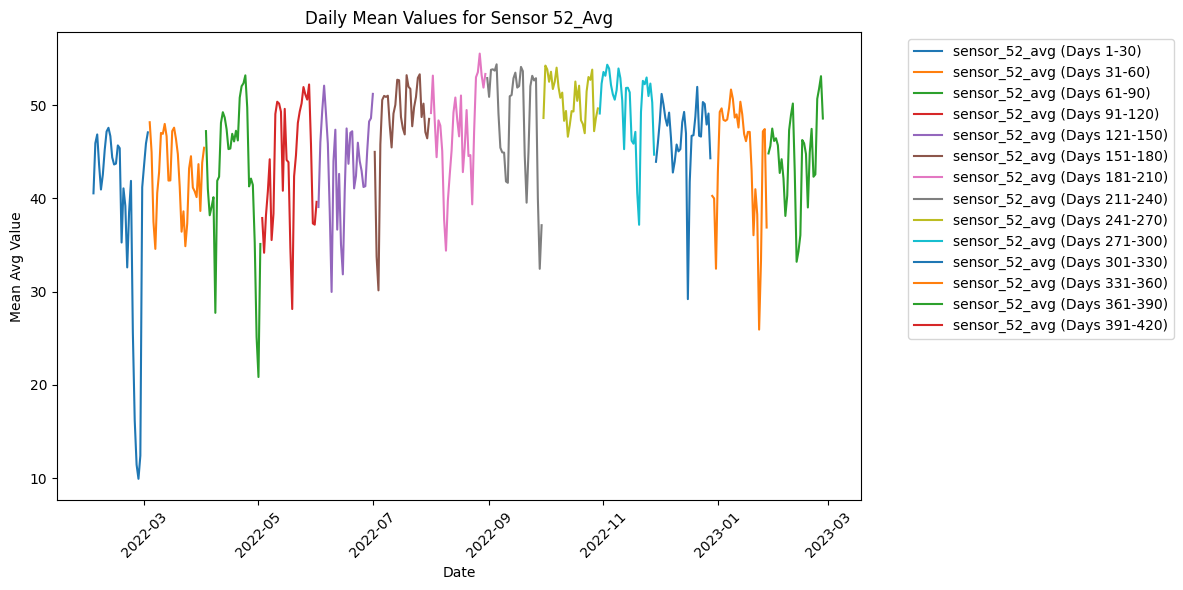

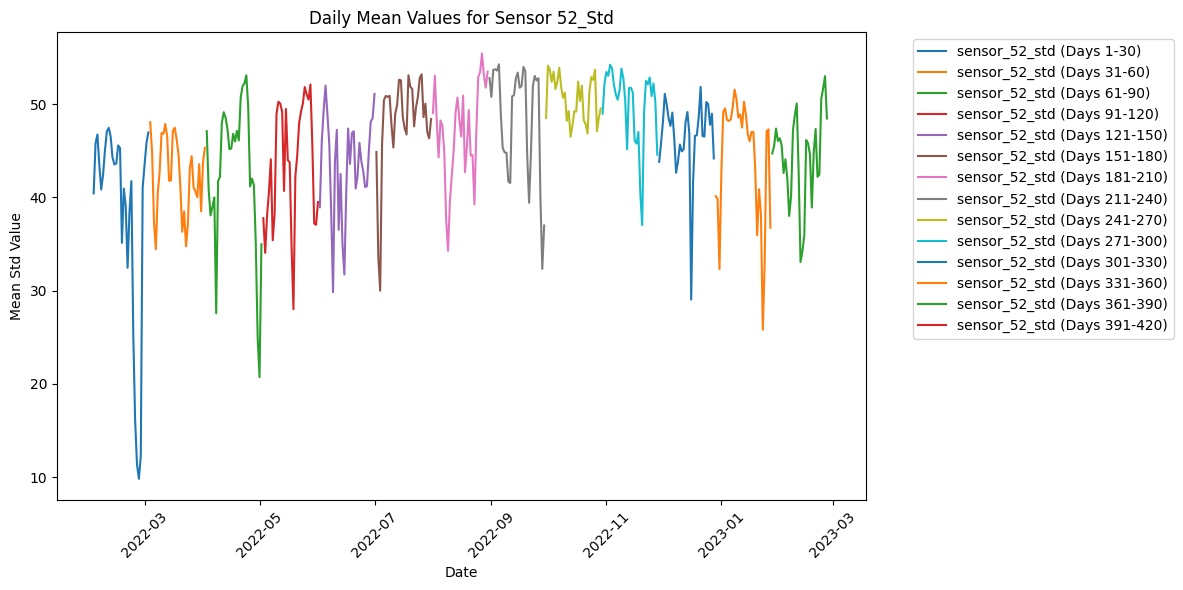

In [38]:
#Author : Gauri and Rinkal
import pandas as pd
import matplotlib.pyplot as plt
import random

# Ensure 'time_stamp' is in datetime format
timestamp_copy = pd.to_datetime(df['time_stamp'])  # Convert without modifying the original DataFrame

# Identify sensor columns with 'min', 'max', 'avg', and 'std'
sensor_columns = [col for col in df.columns if 'sensor_' in col and ('_min' in col or '_max' in col or '_avg' in col or '_std' in col)]

# Extract unique sensor IDs
sensor_ids = list(set(col.split('_')[1] for col in sensor_columns))

# Randomly select 4 sensor IDs
random_sensor_ids = random.sample(sensor_ids, 4)

# Create a temporary DataFrame with 'time_stamp' and selected columns
temp_df = pd.concat([timestamp_copy, df[sensor_columns]], axis=1)
temp_df.rename(columns={'time_stamp': 'timestamp'}, inplace=True)

# Group data by day and calculate the mean for each day
daily_mean = temp_df.groupby(temp_df['timestamp'].dt.date).mean()

# Split the data into groups of 30 days
num_days = len(daily_mean)
num_groups = (num_days + 29) // 30  # Calculate number of groups (ceil division)

# Plot for each randomly selected sensor ID
for sensor_id in random_sensor_ids:
    # Get the `min`, `max`, `avg`, and `std` columns for the current sensor
    sensor_group = [col for col in sensor_columns if f'sensor_{sensor_id}_' in col]

    # Plot each metric separately for the current sensor
    for metric in ['min', 'max', 'avg', 'std']:
        metric_columns = [col for col in sensor_group if f'_{metric}' in col]

        if metric_columns:  # Ensure the metric exists
            plt.figure(figsize=(12, 6))

            # Iterate over each group of 30 days
            for i in range(num_groups):
                start_day = i * 30
                end_day = start_day + 30
                group_data = daily_mean.iloc[start_day:end_day]

                # Plot the mean values for the current metric
                for col in metric_columns:
                    plt.plot(group_data.index, group_data[col], label=f'{col} (Days {start_day + 1}-{end_day})')

            # Customize the plot for the current metric
            plt.title(f"Daily Mean Values for Sensor {sensor_id}_{metric.capitalize()}")
            plt.xlabel("Date")
            plt.ylabel(f"Mean {metric.capitalize()} Value")
            plt.xticks(rotation=45)
            plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Move legend outside the plot
            plt.tight_layout()
            plt.show()


# Box plot for randomly taken 5 sensors

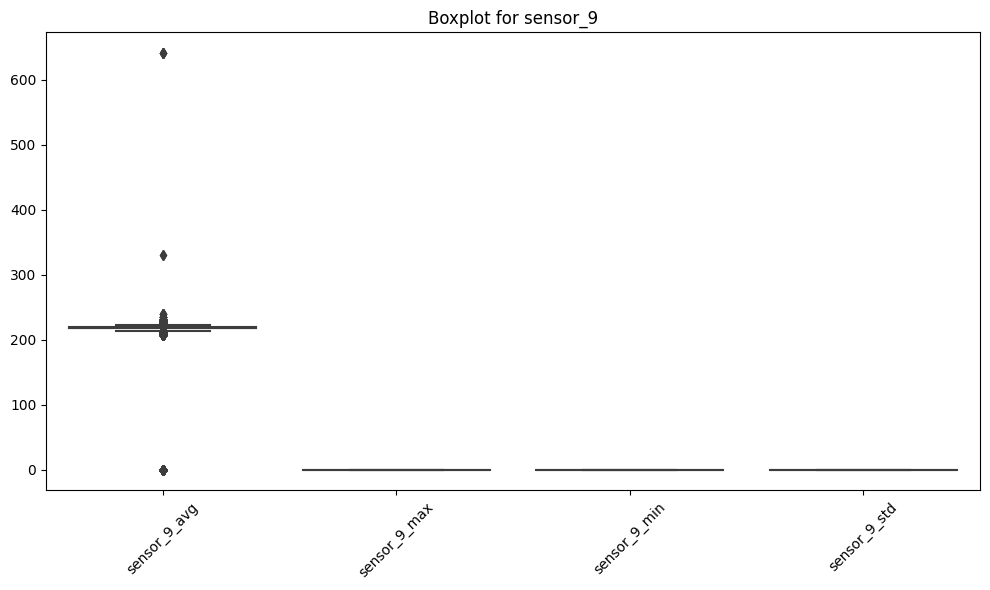

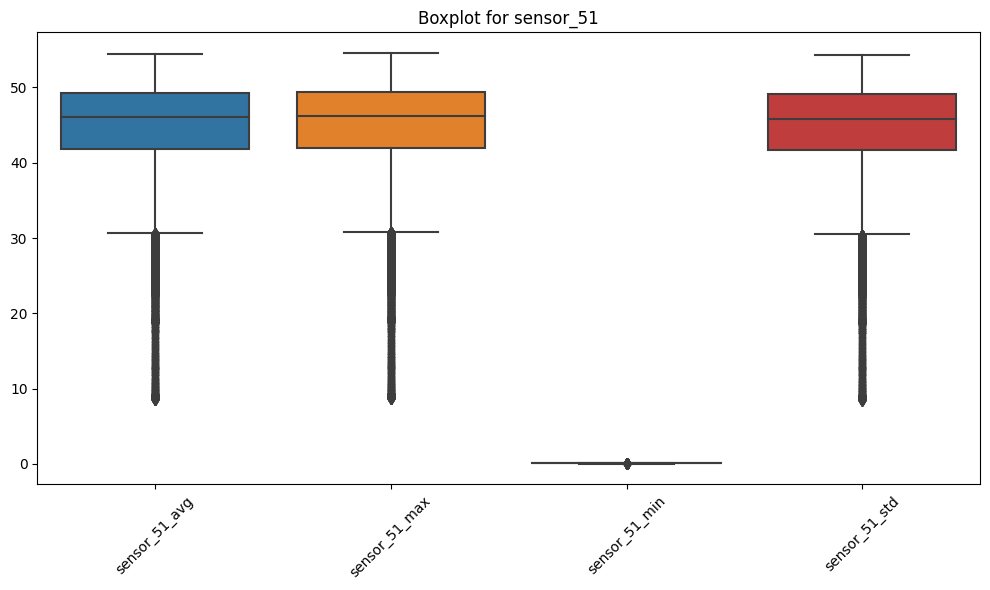

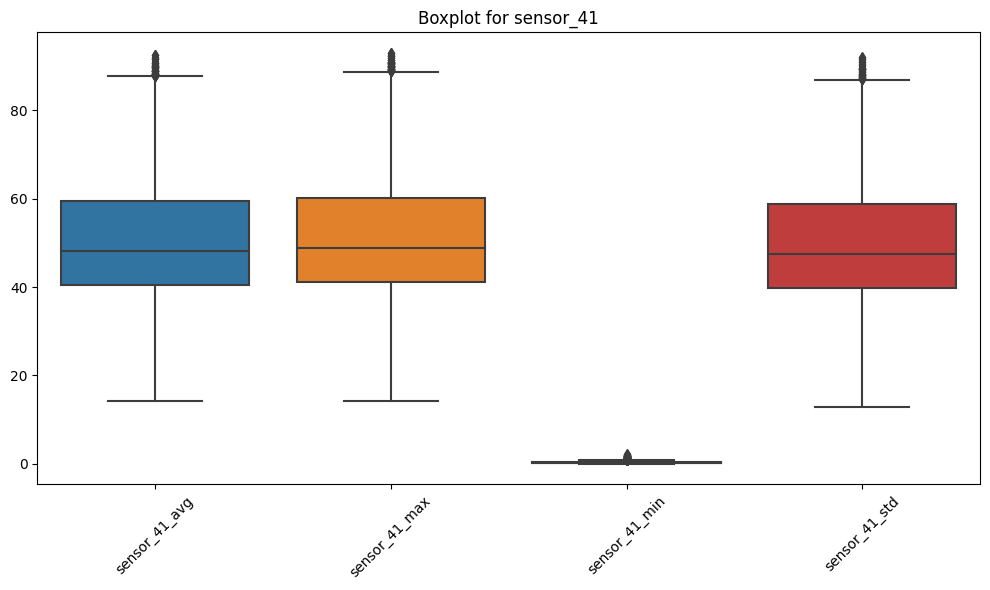

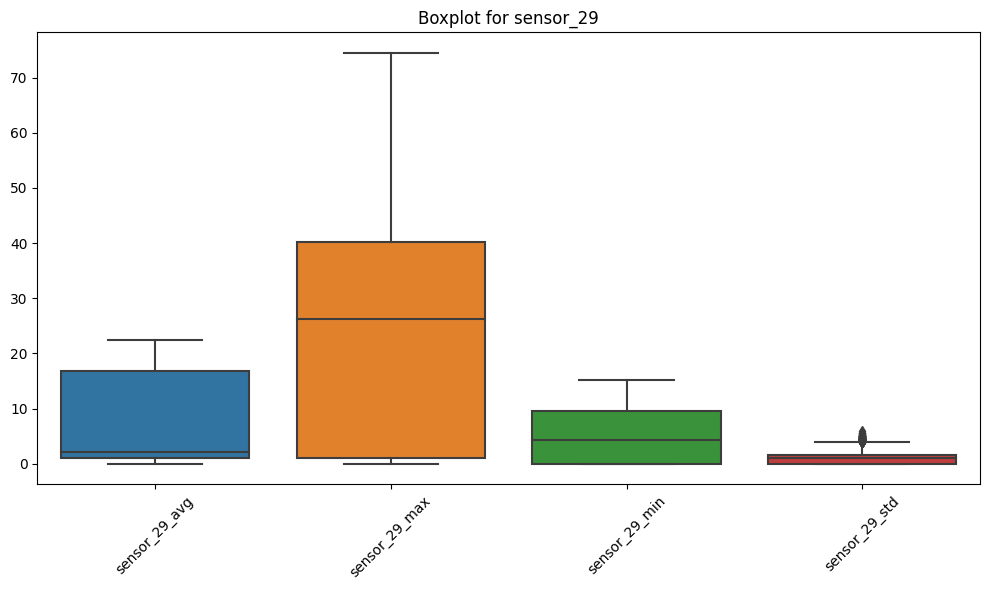

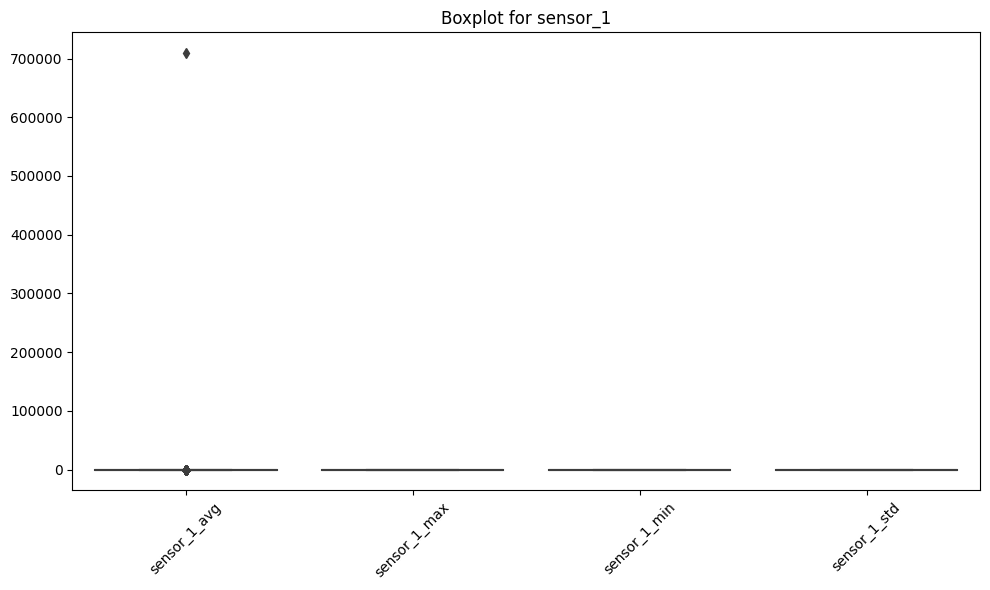

In [39]:
#Author : Gauri and Rinkal
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random

# Assuming df is your dataset
sensor_columns = [col for col in df.columns if 'sensor_' in col]  # Identify sensor columns

# Group the sensor columns into 4 columns per sensor (max, min, avg, std)
sensor_groups = [sensor_columns[i:i + 4] for i in range(0, len(sensor_columns), 4)]

# Randomly select 5 sensor groups
random_sensor_groups = random.sample(sensor_groups, 5)

# Loop through each selected group and create a boxplot
for group in random_sensor_groups:  # Iterate over the selected groups
    plt.figure(figsize=(10, 6))  # Create a new figure for each sensor group
    sns.boxplot(data=df[group])
    
    # Extract the sensor name from the first column (e.g., 'sensor_0')
    sensor_name = group[0].split('_')[0] + '_' + group[0].split('_')[1]  # This gets 'sensor_0', 'sensor_1', etc.
    
    plt.title(f'Boxplot for {sensor_name}')  # Title based on sensor group
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()  # Show the box plot for the current group


In [40]:
# import numpy as np

# # Exclude non-numerical columns
# numerical_df = df.select_dtypes(include=[np.number])

# # Compute the correlation matrix
# correlation_matrix = numerical_df.corr().abs()

# # Create an upper triangle mask with boolean values
# mask = np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)

# # Apply the mask to the correlation matrix
# upper_triangle = correlation_matrix.where(mask)

# # Select columns with high correlation
# to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]

# # Drop the identified columns from the original DataFrame
# df = df.drop(columns=to_drop)

# print(f"Removed columns: {to_drop}")

# # Verify the remaining columns
# print(f"Remaining columns: {df.columns.tolist()}")


# Kmeans with pca transformed features

In [41]:
#Author : Gauri 
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Assuming 'df' contains your dataset with 'datetime', 'train_test', and numerical columns

# Step 1: Separate train and test data
train_data = df[df['train_test'] == 'train'].copy()
test_data = df[df['train_test'] == 'prediction'].copy()

# Step 2: Standardize numerical columns (excluding 'datetime', 'train_test') and one-hot encode 'status_type_id'
excluded_cols = ['status_type_id']
numerical_cols = [
    col for col in train_data.select_dtypes(include='number').columns if col not in excluded_cols
]
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_data[numerical_cols])
test_scaled = scaler.transform(test_data[numerical_cols])

# One-hot encode 'status_type_id'
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop='first')
train_ohe = ohe.fit_transform(train_data[['status_type_id']])
test_ohe = ohe.transform(test_data[['status_type_id']])

# Combine scaled numerical data and one-hot encoded categorical data
train_scaled = np.hstack((train_scaled, train_ohe))
test_scaled = np.hstack((test_scaled, test_ohe))

# Step 3: Apply PCA for feature extraction
pca = PCA(n_components=0.95)  # Preserve 95% of the variance
train_pca = pca.fit_transform(train_scaled)
test_pca = pca.transform(test_scaled)

# Step 4: Apply KMeans with different values of 'n_clusters'
best_score = -1
best_kmeans = None
best_n_clusters = 2  # initial value

# Try different values for 'n_clusters'
for n_clusters in range(2, 11):  # Try clustering from 2 to 10 clusters
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(train_pca)
    
    # Calculate silhouette score
    score = silhouette_score(test_pca, kmeans.predict(test_pca))
    
    if score > best_score:
        best_score = score
        best_kmeans = kmeans
        best_n_clusters = n_clusters

# Check if a valid KMeans model was found
if best_kmeans is None:
    print("No valid KMeans configuration found. Please adjust 'n_clusters'.")
else:
    # Fit the optimized KMeans model
    train_data['cluster'] = best_kmeans.fit_predict(train_pca)
    test_data['cluster'] = best_kmeans.predict(test_pca)

    # Evaluate silhouette score on both train and test data
    train_silhouette = silhouette_score(train_pca, train_data['cluster'])
    test_silhouette = silhouette_score(test_pca, test_data['cluster'])

    # Step 5: Display results and silhouette score
    print(f"Optimal n_clusters: {best_n_clusters}")
    print(f"Train Silhouette Score: {train_silhouette:.4f}")
    print(f"Test Silhouette Score: {test_silhouette:.4f}")
    print("\nTest Data with Regions:")
    print(test_data[['time_stamp', 'cluster']].head())


Optimal n_clusters: 2
Train Silhouette Score: 0.2576
Test Silhouette Score: 0.3905

Test Data with Regions:
                time_stamp  cluster
52529  2023-02-01 00:00:00        1
52530  2023-02-01 00:10:00        1
52531  2023-02-01 00:20:00        1
52532  2023-02-01 00:30:00        1
52533  2023-02-01 00:40:00        1


# checking Davies-bouldin index

In [43]:
#Author : Gauri 
from sklearn.metrics import davies_bouldin_score

# Compute Davies-Bouldin Index for your test data clustering
dbi = davies_bouldin_score(test_scaled, test_data['cluster'])
print(f"Davies-Bouldin Index: {dbi:.4f}")


Davies-Bouldin Index: 1.1218


# 2d clusters plotting by PCA

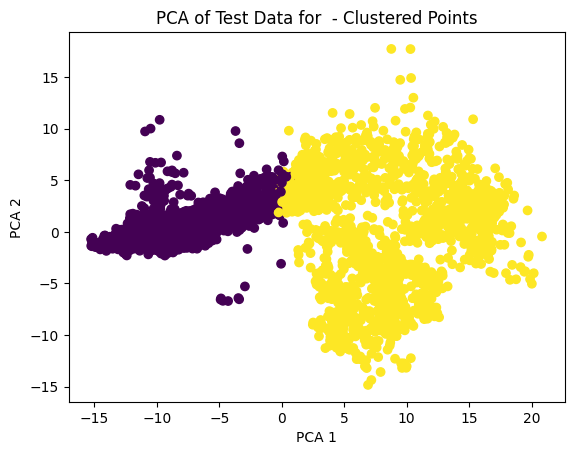

In [44]:
#Author : Gauri 
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
reduced_data = pca.fit_transform(test_scaled)

plt.scatter(reduced_data[:, 0], reduced_data[:, 1], c=test_data['cluster'], cmap='viridis')
plt.title("PCA of Test Data for  - Clustered Points")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()


# 3D clusters plotting by PCA

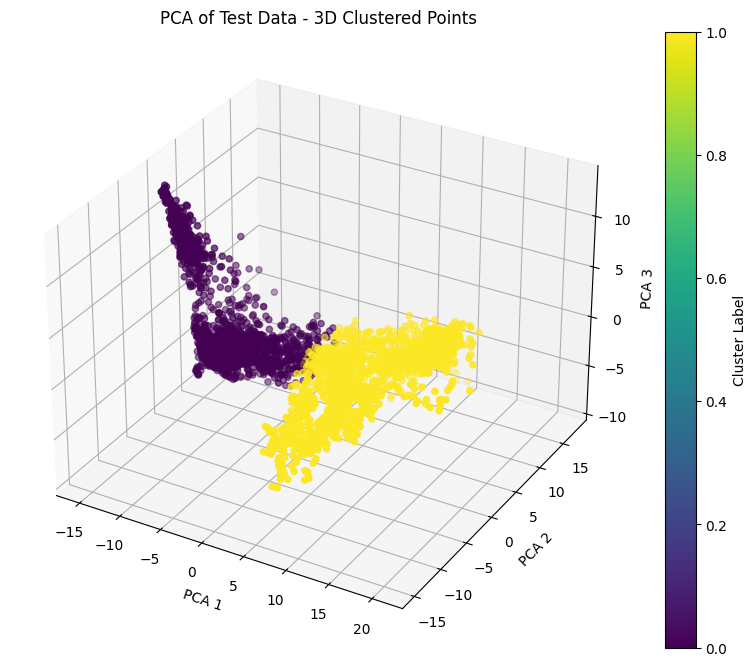

In [45]:
#Author : Gauri 
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Perform PCA to reduce data to 3 components
pca = PCA(n_components=3)
reduced_data = pca.fit_transform(test_scaled)

# Create a 3D scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of the reduced data with colors based on cluster labels
scatter = ax.scatter(reduced_data[:, 0], reduced_data[:, 1], reduced_data[:, 2], 
                     c=test_data['cluster'], cmap='viridis')

# Labels and title
ax.set_title("PCA of Test Data - 3D Clustered Points")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

# Add color bar for the clusters
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Cluster Label')

plt.show()


# Anomaly detection for test data points

In [46]:
#Author : Gauri 
# Step 6: Get the centroids of the clusters
centroids = best_kmeans.cluster_centers_

# Step 7: Calculate distance from each test point to all cluster centroids
test_distances = np.linalg.norm(test_pca[:, np.newaxis] - centroids, axis=2)

# Step 8: Assign each test point to the nearest cluster (cluster with the minimum distance)
assigned_clusters = np.argmin(test_distances, axis=1)

# Step 9: Calculate the distance of each test point from its assigned cluster's centroid
assigned_centroids = centroids[assigned_clusters]
distances_from_centroid = np.linalg.norm(test_pca - assigned_centroids, axis=1)

# Step 10: Set a threshold for anomaly detection (e.g., 95th percentile of the distances)
threshold = np.percentile(distances_from_centroid, 95)

# Step 11: Assign "Anomaly" or "Normal" based on the threshold
test_data['region'] = np.where(distances_from_centroid > threshold, 'Anomaly', 'Normal')

# Step 12: Display results
print(f"Number of anomalies in the test data: {test_data[test_data['region'] == 'Anomaly'].shape[0]}")

# Display the results with 'region' column
print("\nTest Data with Region (Anomaly/Normal):")
print(test_data[['time_stamp', 'cluster', 'region']].head())


Number of anomalies in the test data: 188

Test Data with Region (Anomaly/Normal):
                time_stamp  cluster  region
52529  2023-02-01 00:00:00        1  Normal
52530  2023-02-01 00:10:00        1  Normal
52531  2023-02-01 00:20:00        1  Normal
52532  2023-02-01 00:30:00        1  Normal
52533  2023-02-01 00:40:00        1  Normal


In [47]:
pip install ruptures

Note: you may need to restart the kernel to use updated packages.


# change point detection by Dynamic Programming(PELT) algorithm

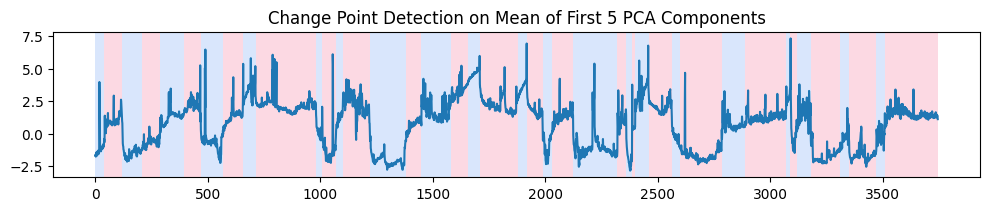

Change from index 655 to 715: Change from Normal to Anomaly
Change from index 980 to 1010: Change from Anomaly to Normal
Change from index 1070 to 1100: Change from Normal to Anomaly
Change from index 1100 to 1220: Change from Anomaly to Normal
Change from index 1380 to 1450: Change from Normal to Anomaly
Change from index 1920 to 1990: Change from Anomaly to Normal
Change from index 2385 to 2400: Change from Normal to Anomaly
Change from index 2460 to 2565: Change from Anomaly to Normal
Change from index 3070 to 3090: Change from Normal to Anomaly
Change from index 3090 to 3120: Change from Anomaly to Normal


In [48]:
#Author : Gauri 
import numpy as np
import ruptures as rpt
import matplotlib.pyplot as plt


# Compute the mean of the first 5 PCA components
signal = test_pca[:, :5].mean(axis=1)

# Apply the PELT algorithm
model = "rbf"
algo = rpt.Pelt(model=model).fit(signal)
change_points = algo.predict(pen=10)

# Visualize the change points
rpt.display(signal, change_points)
plt.title("Change Point Detection on Mean of First 5 PCA Components")
plt.show()

# Assuming that we classify data into 'Normal' (0) and 'Anomaly' (1)
# Set threshold to classify the signal as 'Normal' or 'Anomaly'
threshold = np.percentile(signal, 80)  # Anomaly is anything above the 95th percentile
labels = np.where(signal > threshold, 'Anomaly', 'Normal')  # Map to labels

# Step 1: Detect transitions around the change points
transition_labels = []

# Loop through the change points and check for transitions
for i in range(1, len(change_points)):
    start = change_points[i - 1]
    end = change_points[i]

    # Ensure 'end' does not go out of bounds
    if end >= len(labels):
        end = len(labels) - 1

    # Get the label before and after the change point
    start_label = labels[start]  # Label at the start of the segment
    end_label = labels[end]      # Label at the end of the segment

    # Detect transitions and record the change from Normal to Anomaly or vice versa
    if start_label != end_label:
        transition = f"Change from {start_label} to {end_label}"
        transition_labels.append((start, end, transition))

# Step 2: Output the results for each change point
if transition_labels:
    for start, end, transition in transition_labels:
        print(f"Change from index {start} to {end}: {transition}")
else:
    print("No transitions detected.")



# Accuracy calculation by considering Normal data points in true label

In [49]:
#Author : Gauri 
from sklearn.metrics import confusion_matrix

# Step 1: Map the 'status_type_id' values to 'normal' and 'anomaly' for ground truth
test_data['true_label'] = test_data['status_type_id'].apply(lambda x: 'Normal' if x in [0, 2] else 'Anomaly')

# Step 2: Filter the data to only include "normal" behavior (status_type_id in [0, 2])
normal_data = test_data[test_data['true_label'] == 'Normal']

# Step 3: Calculate confusion matrix only for normal data
conf_matrix = confusion_matrix(normal_data['true_label'], normal_data['region'], labels=['Normal', 'Anomaly'])

# Extract True Negatives (TN) and False Positives (FP)
tn, fp, _, _ = conf_matrix.ravel()

# Step 4: Calculate Accuracy for normal behavior data
accuracy = tn / (tn + fp)  # Accuracy formula for normal behavior only
# Output the result
print(f"Accuracy (considering only normal behavior): {accuracy:.2f}")

Accuracy (considering only normal behavior): 0.96


# Plotting Confusion Matrix by taking Normal datapoints in true label

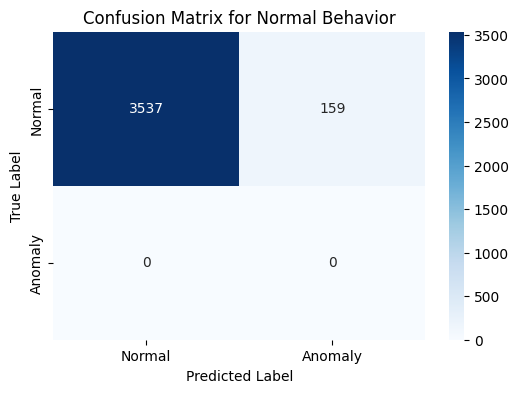

In [50]:
#Author : Gauri 
# Step 3: Plot confusion matrix using seaborn
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])

# Labels and title
plt.title('Confusion Matrix for Normal Behavior')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Show plot
plt.show()